In [1]:
# ============================================================
# 0. IMPORTS & CONFIGURATION
# ============================================================
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV,
)
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, HistGradientBoostingClassifier,
    GradientBoostingClassifier,
)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, roc_auc_score,
    roc_curve, f1_score, precision_score, recall_score,
    matthews_corrcoef, balanced_accuracy_score,
)
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PALETTE = {
    "fraud":   "#e74c3c", "legit":   "#2ecc71",
    "primary": "#3498db", "accent":  "#f39c12",
    "dark":    "#2c3e50", "gray":    "#95a5a6",
    "retained": "#27ae60", "rejected": "#bdc3c7",
}

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6), "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.labelsize": 11,
    "legend.fontsize": 9,
})

for d in ("models", "figures"):
    Path(d).mkdir(exist_ok=True)

print(f"✓ Imports OK — RANDOM_STATE = {RANDOM_STATE}")

✓ Imports OK — RANDOM_STATE = 42


In [2]:
# ============================================================
# 1. CHARGEMENT
# ============================================================
data = pd.read_csv("credit/credit_card_fraud_2026.csv")

print(f"Dataset    : {data.shape[0]:,} lignes × {data.shape[1]} colonnes")
print(f"Fraudes    : {data['is_fraud'].sum():,} ({data['is_fraud'].mean()*100:.2f} %)")
print(f"Mémoire    : {data.memory_usage(deep=True).sum() / 1e6:.1f} Mo")
data.head(3)

Dataset    : 20,000 lignes × 26 colonnes
Fraudes    : 339 (1.70 %)
Mémoire    : 4.1 Mo


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0


In [3]:
# ============================================================
# 2. AUDIT — TYPES, MANQUANTS, DOUBLONS
# ============================================================
audit = pd.DataFrame({
    "type":        data.dtypes,
    "n_unique":    data.nunique(),
    "n_missing":   data.isnull().sum(),
    "pct_missing": (data.isnull().mean() * 100).round(2),
})

print(f"Valeurs manquantes : {audit['n_missing'].sum()}")
print(f"Doublons           : {data.duplicated().sum()}")
print("\nRépartition par type :")
print(audit["type"].value_counts().to_string())
audit

Valeurs manquantes : 0
Doublons           : 0

Répartition par type :
type
int64      9
float64    6
bool       6
str        5


,type,n_unique,n_missing,pct_missing
transaction_id,int64,20000,0,0.0
amount_usd,float64,12782,0,0.0
merchant_category,str,12,0,0.0
card_type,str,5,0,0.0
auth_method,str,5,0,0.0
channel,str,5,0,0.0
device_type,str,8,0,0.0
is_foreign_transaction,bool,2,0,0.0
hours_since_last_txn,float64,3296,0,0.0
txn_count_last_24h,int64,13,0,0.0


In [4]:
# ============================================================
# 3. SÉPARATION STRATIFIÉE TRAIN / VALIDATION / TEST
# ============================================================
# La séparation est faite AVANT toute décision de prétraitement :
# - Train (64 %) : entraînement + CV interne
# - Validation (16 %) : choix du seuil
# - Test (20 %) : évaluation finale, une seule fois
X = data.drop(columns=["transaction_id", "is_fraud"])
y = data["is_fraud"].astype(int)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.20, stratify=y_train_val, random_state=RANDOM_STATE)

print(f"{'Ensemble':<12}{'Lignes':>10}{'Fraudes':>10}{'Taux':>10}")
print("-" * 42)
for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<12}{len(yy):>10,}{yy.sum():>10,}{yy.mean()*100:>9.2f} %")

# Identification des types de colonnes
num_cols  = X_train.select_dtypes(include=np.number).columns.tolist()
bool_cols = X_train.select_dtypes(include=["bool"]).columns.tolist()
cat_cols  = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

# Vérification : un booléen peut être vu comme numérique par pandas
overlap = set(num_cols) & set(bool_cols)
if overlap:
    num_cols = [c for c in num_cols if c not in overlap]
assert not (set(num_cols) & set(bool_cols))
assert not (set(num_cols) & set(cat_cols))
assert not (set(bool_cols) & set(cat_cols))

print(f"\nVariables : {len(num_cols)} numériques, {len(cat_cols)} catégorielles, "
      f"{len(bool_cols)} booléennes")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Ensemble        Lignes   Fraudes      Taux
------------------------------------------
Train           12,800       217     1.70 %
Validation       3,200        54     1.69 %
Test             4,000        68     1.70 %

Variables : 13 numériques, 5 catégorielles, 6 booléennes


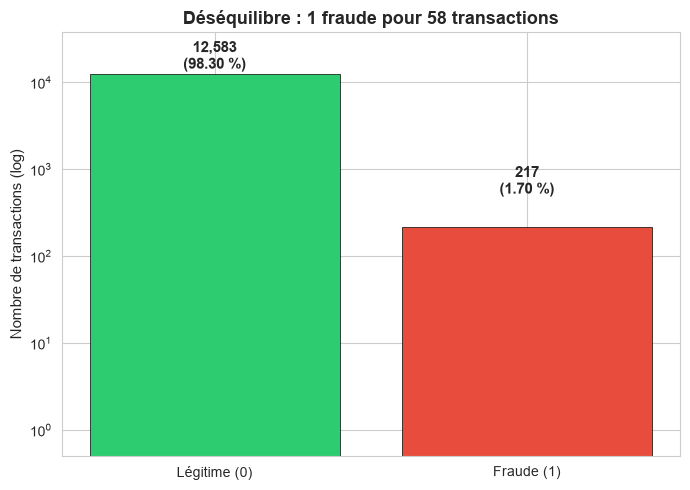

→ Ratio : 1 : 58 | Métrique principale : PR-AUC


In [5]:
# ============================================================
# 4.1 EDA — DÉSÉQUILIBRE
# ============================================================
eda_data = X_train.copy()
eda_data["is_fraud"] = y_train

counts = eda_data["is_fraud"].value_counts().sort_index()
ratio  = counts[0] / counts[1]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(["Légitime (0)", "Fraude (1)"], counts.values,
              color=[PALETTE["legit"], PALETTE["fraud"]],
              edgecolor="black", linewidth=0.5)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + counts.max()*0.02,
            f"{v:,}\n({v/len(eda_data)*100:.2f} %)", ha="center", va="bottom",
            fontsize=11, fontweight="bold")
ax.set_yscale("log")
ax.set_ylabel("Nombre de transactions (log)")
ax.set_title(f"Déséquilibre : 1 fraude pour {ratio:.0f} transactions")
ax.set_ylim(0.5, counts.max()*3)
plt.tight_layout()
plt.savefig("figures/01_desequilibre.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"→ Ratio : 1 : {ratio:.0f} | Métrique principale : PR-AUC")

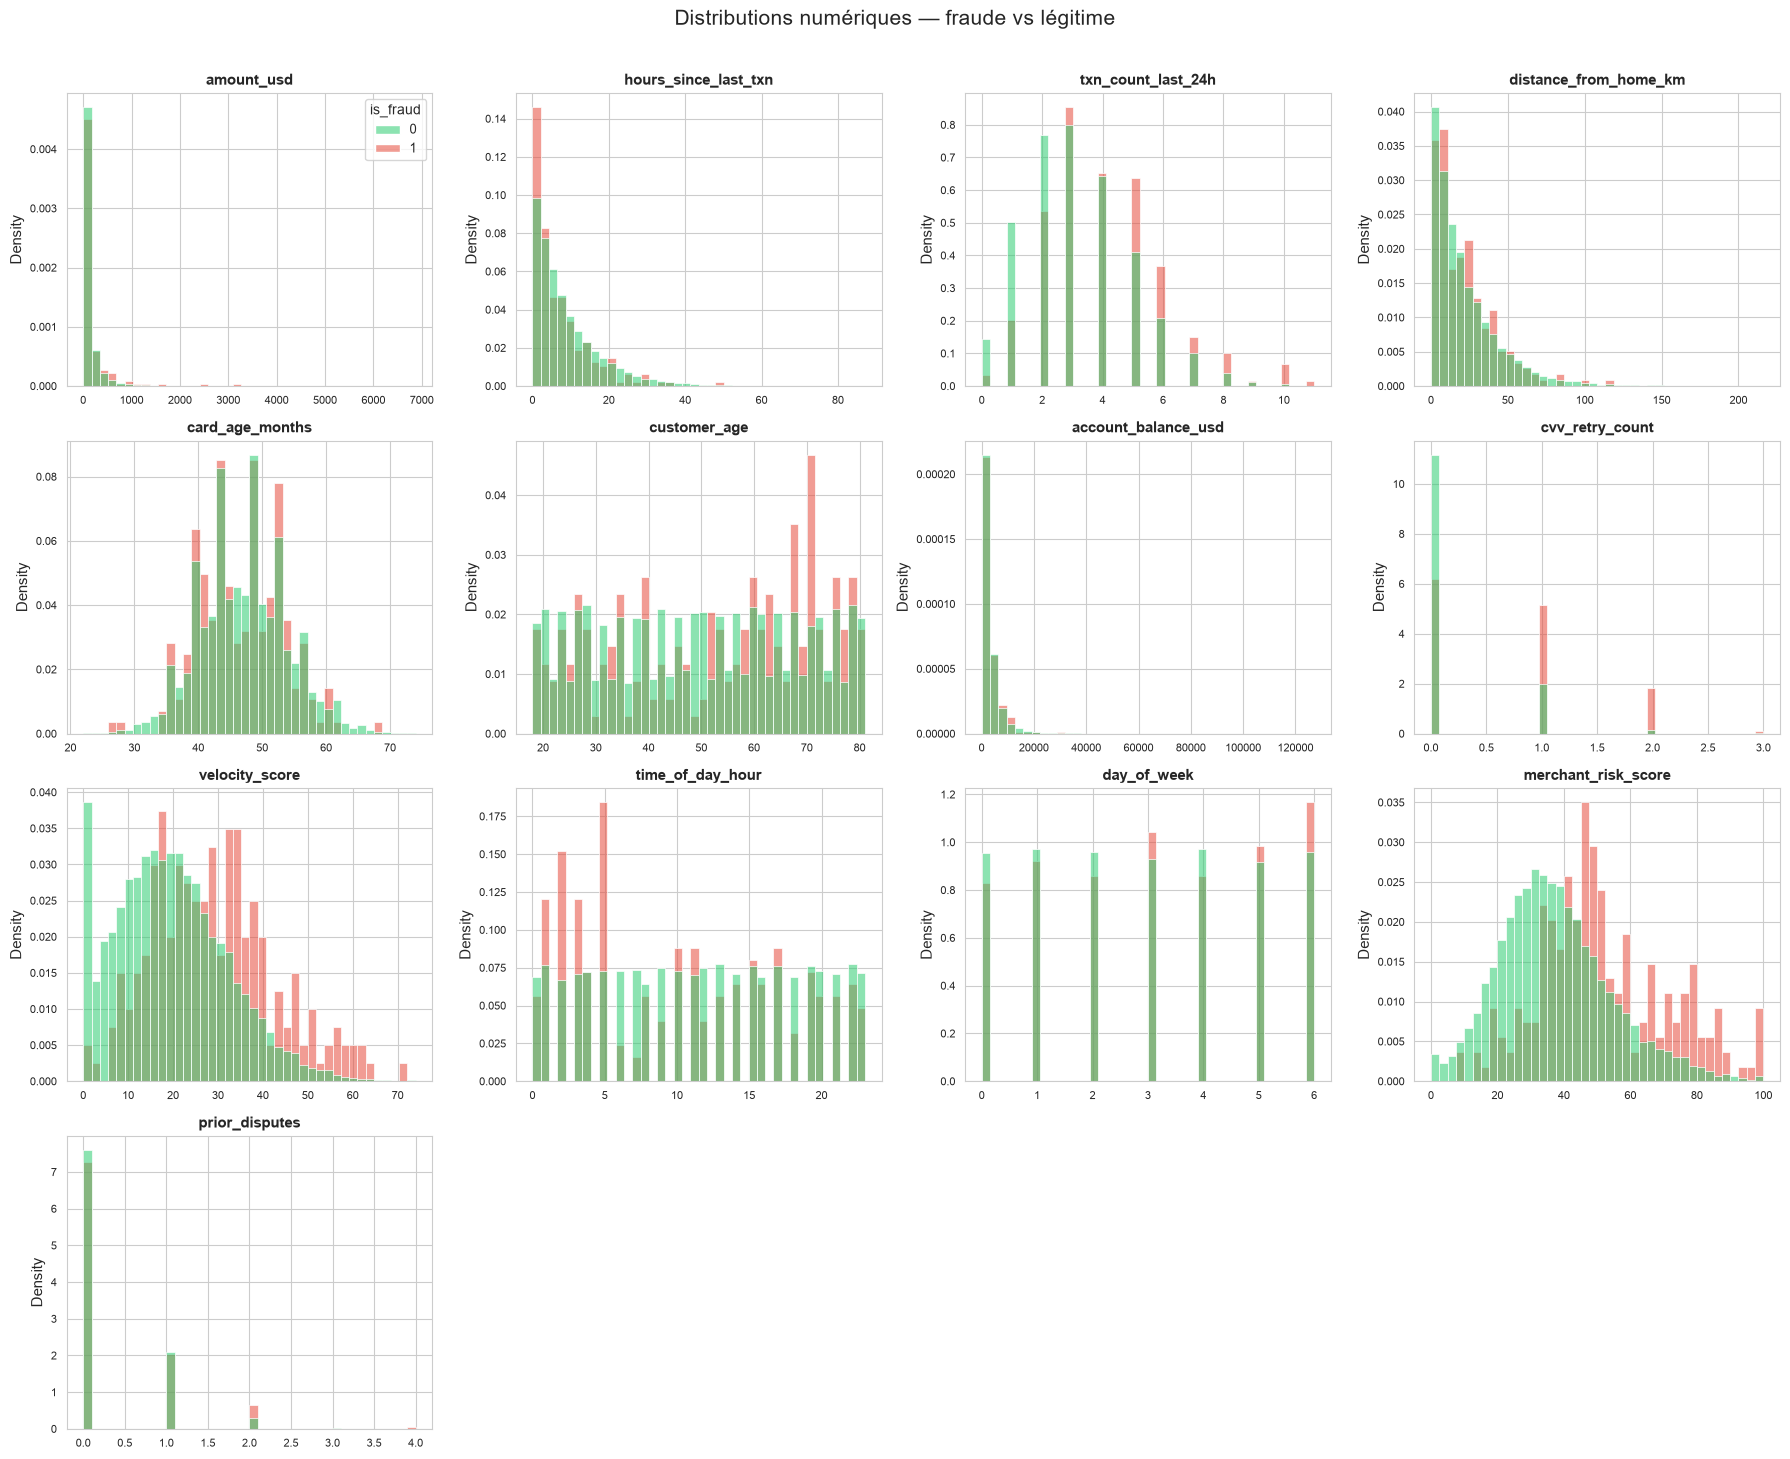

In [6]:
# ============================================================
# 4.2 EDA — DISTRIBUTIONS NUMÉRIQUES
# ============================================================
num_cols_eda = [c for c in eda_data.select_dtypes(include=np.number).columns
                if c not in ("is_fraud",)]
n = len(num_cols_eda)
ncols, nrows = 4, int(np.ceil(n / 4))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.6 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols_eda):
    sns.histplot(data=eda_data, x=col, hue="is_fraud", bins=40,
                 stat="density", common_norm=False,
                 palette={0: PALETTE["legit"], 1: PALETTE["fraud"]},
                 alpha=0.55, ax=axes[i], legend=(i == 0))
    axes[i].set_title(col, fontsize=11); axes[i].set_xlabel("")
    axes[i].tick_params(labelsize=8)
for j in range(i + 1, len(axes)): axes[j].axis("off")

plt.suptitle("Distributions numériques — fraude vs légitime", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig("figures/02_hist_numeriques.png", dpi=120, bbox_inches="tight")
plt.show()

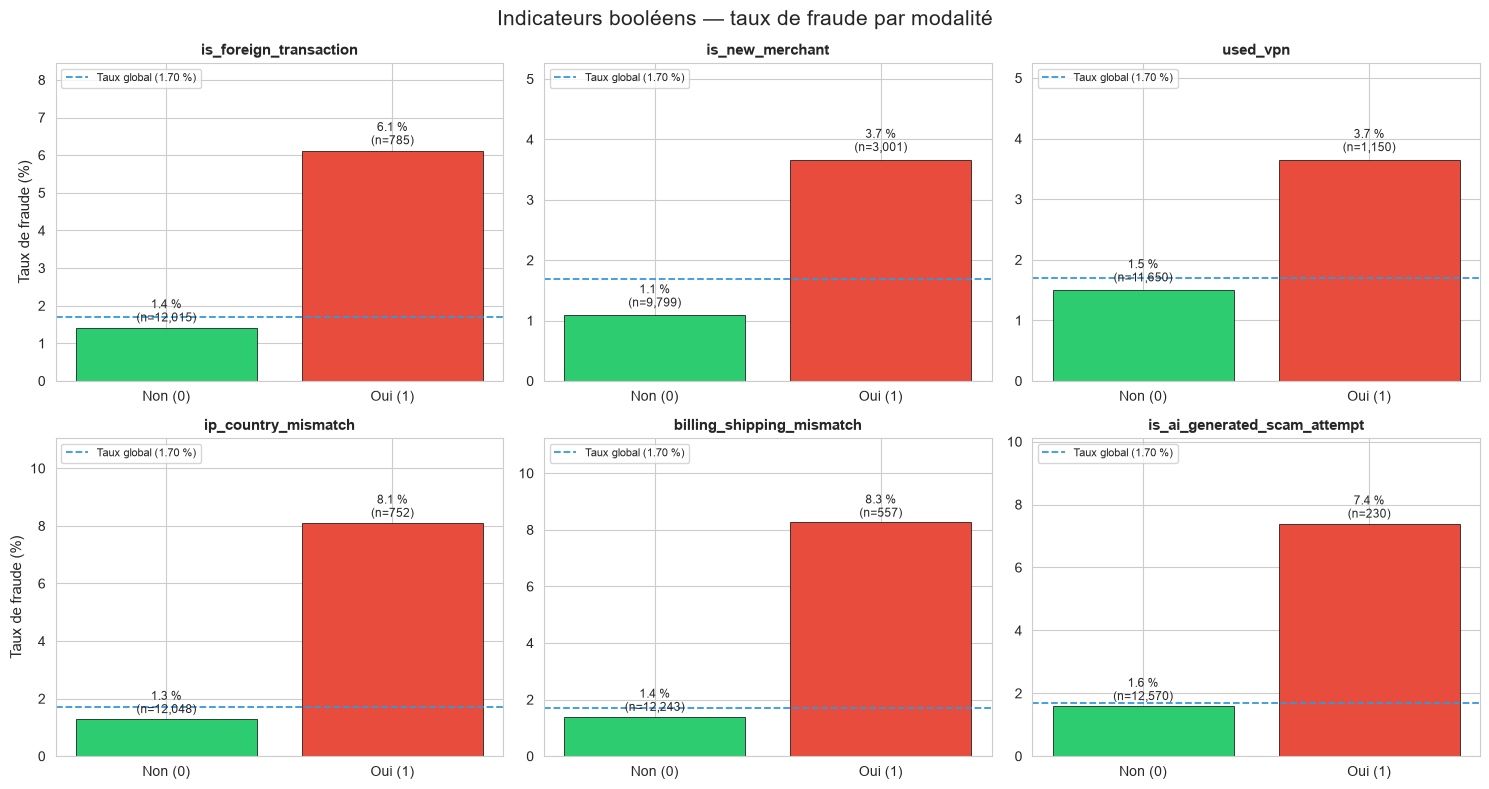

In [7]:
# ============================================================
# 4.3 EDA — INDICATEURS BOOLÉENS
# ============================================================
bool_cols_eda = eda_data.select_dtypes(include="bool").columns.tolist()
global_rate = eda_data["is_fraud"].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(bool_cols_eda):
    taux     = eda_data.groupby(col)["is_fraud"].mean() * 100
    effectif = eda_data.groupby(col)["is_fraud"].count()
    bars = axes[i].bar(["Non (0)", "Oui (1)"], taux.values,
                       color=[PALETTE["legit"], PALETTE["fraud"]],
                       edgecolor="black", linewidth=0.5)
    axes[i].axhline(global_rate, color=PALETTE["primary"], ls="--", lw=1.3,
                    label=f"Taux global ({global_rate:.2f} %)")
    for bar, v, nn in zip(bars, taux.values, effectif.values):
        axes[i].text(bar.get_x() + bar.get_width()/2, v + global_rate*0.05,
                     f"{v:.1f} %\n(n={nn:,})", ha="center", va="bottom", fontsize=8.5)
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel("Taux de fraude (%)" if i % 3 == 0 else "")
    axes[i].legend(fontsize=8, loc="upper left")
    axes[i].set_ylim(0, max(taux.max(), global_rate)*1.3 + 0.5)
plt.suptitle("Indicateurs booléens — taux de fraude par modalité", fontsize=15)
plt.tight_layout()
plt.savefig("figures/03_booleens.png", dpi=120, bbox_inches="tight")
plt.show()

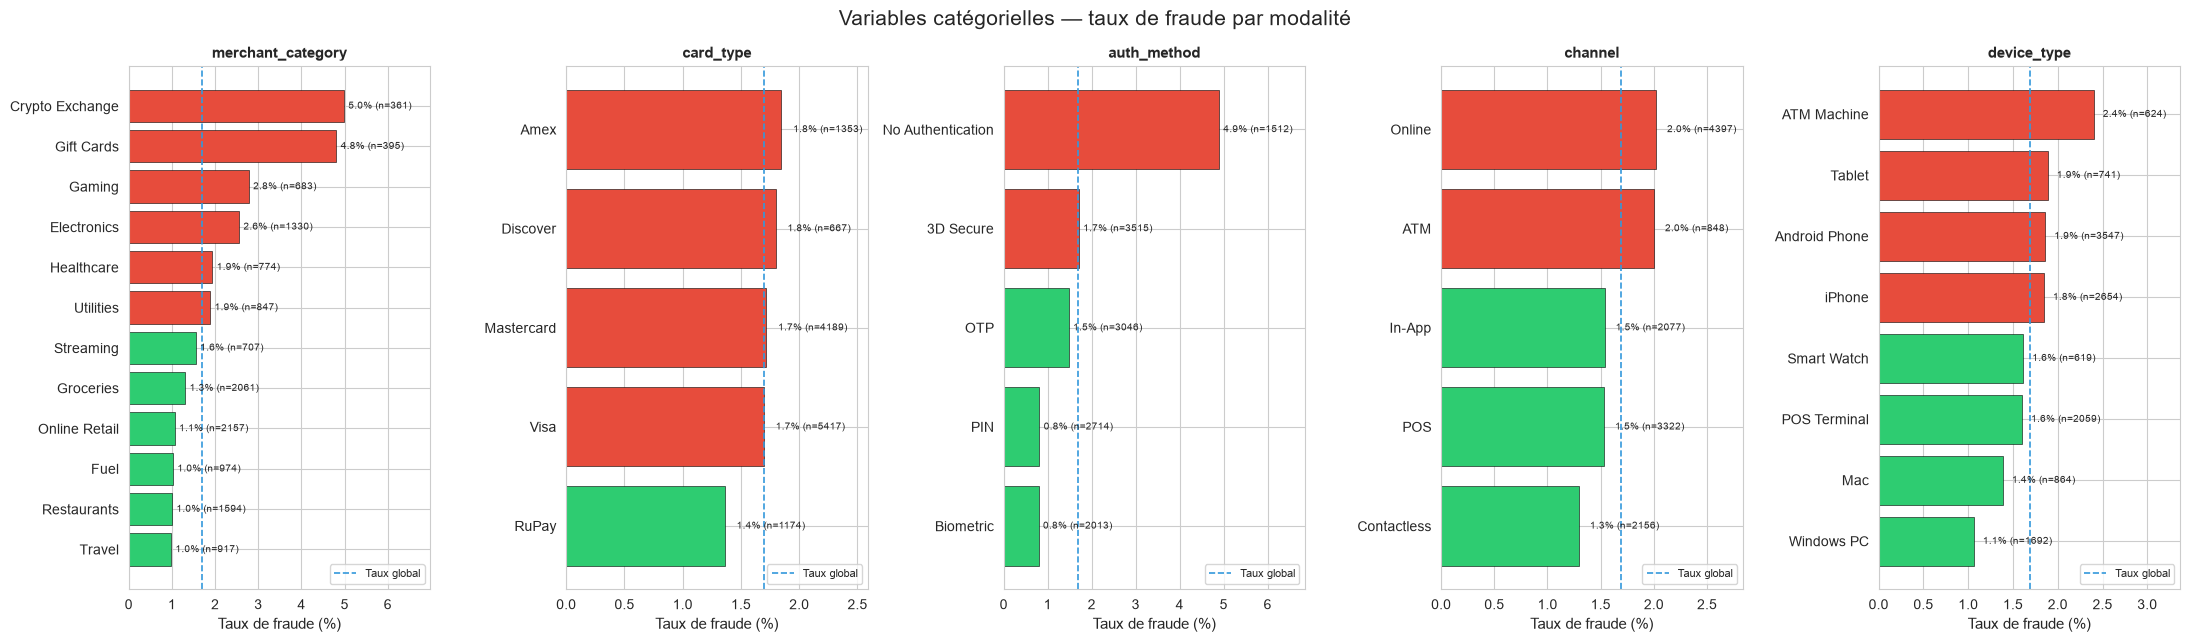

In [8]:
# ============================================================
# 4.4 EDA — VARIABLES CATÉGORIELLES
# ============================================================
cat_cols_eda = eda_data.select_dtypes(include=["object", "string", "category"]).columns.tolist()
fig, axes = plt.subplots(1, len(cat_cols_eda), figsize=(22, 6.5))
if len(cat_cols_eda) == 1:
    axes = [axes]
for i, col in enumerate(cat_cols_eda):
    taux     = eda_data.groupby(col)["is_fraud"].mean().sort_values() * 100
    effectif = eda_data.groupby(col)["is_fraud"].count()
    colors = [PALETTE["fraud"] if v > global_rate else PALETTE["legit"]
              for v in taux.values]
    axes[i].barh(taux.index.astype(str), taux.values,
                 color=colors, edgecolor="black", linewidth=0.4)
    axes[i].axvline(global_rate, color=PALETTE["primary"], ls="--", lw=1.2,
                    label="Taux global")
    axes[i].set_title(col, fontsize=11); axes[i].set_xlabel("Taux de fraude (%)")
    for j, (idx, v) in enumerate(taux.items()):
        axes[i].text(v + 0.1, j, f"{v:.1f}% (n={effectif[idx]})",
                     va="center", fontsize=7.5)
    axes[i].legend(fontsize=8, loc="lower right")
    axes[i].set_xlim(0, taux.max() * 1.4)
plt.suptitle("Variables catégorielles — taux de fraude par modalité", fontsize=15)
plt.tight_layout()
plt.savefig("figures/04_categorielles.png", dpi=120, bbox_inches="tight")
plt.show()

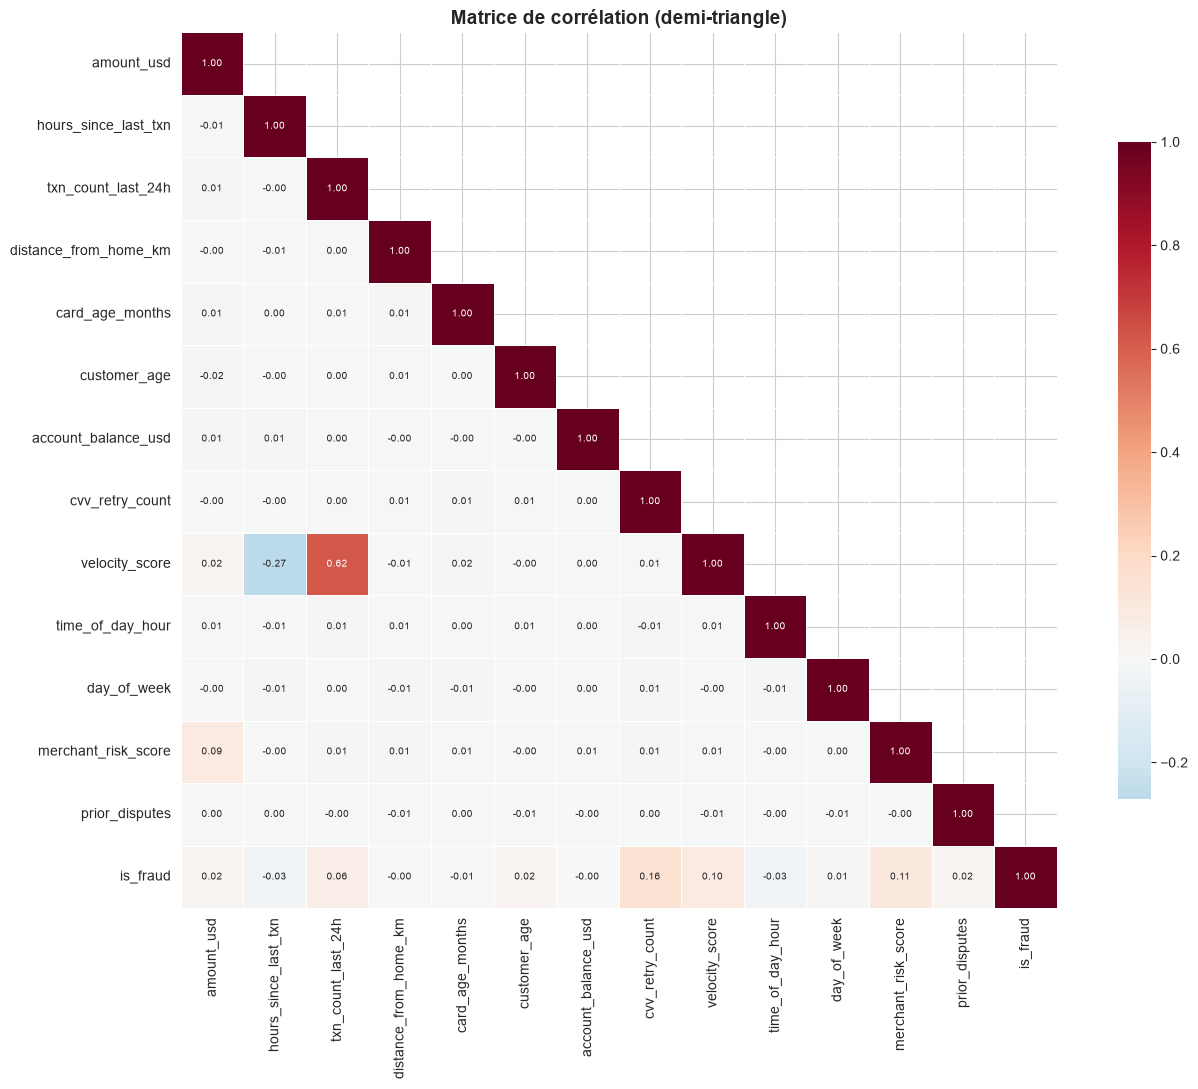


Corrélations avec is_fraud :
cvv_retry_count          0.156
merchant_risk_score      0.108
velocity_score           0.097
txn_count_last_24h       0.063
customer_age             0.024
amount_usd               0.020
prior_disputes           0.019
day_of_week              0.012
distance_from_home_km   -0.003
account_balance_usd     -0.005
card_age_months         -0.009
hours_since_last_txn    -0.027
time_of_day_hour        -0.028


In [9]:
# ============================================================
# 4.5 EDA — CORRÉLATIONS
# ============================================================
num_cols_corr = [c for c in eda_data.select_dtypes(include=np.number).columns]
corr = eda_data[num_cols_corr].corr()
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.75}, annot_kws={"size": 7}, ax=ax)
ax.set_title("Matrice de corrélation (demi-triangle)", fontsize=14)
plt.tight_layout()
plt.savefig("figures/05_correlation.png", dpi=130, bbox_inches="tight")
plt.show()

corr_target = corr["is_fraud"].drop("is_fraud").sort_values(ascending=False)
print("\nCorrélations avec is_fraud :")
print(corr_target.round(3).to_string())

In [10]:
# ============================================================
# 5. FONCTIONS UTILITAIRES
# ============================================================
def engineer_features(df):
    """Crée 10 features dérivées. Les indicateurs binaires restent en int
    pour rester simples — ils seront scalés comme les autres numériques."""
    df = df.copy()
    df["amount_to_balance_ratio"] = df["amount_usd"] / (df["account_balance_usd"] + 1)

    risk_flags = ["is_foreign_transaction", "is_new_merchant", "used_vpn",
                  "ip_country_mismatch", "billing_shipping_mismatch",
                  "is_ai_generated_scam_attempt"]
    df["risk_signal_count"] = df[risk_flags].sum(axis=1).astype(float)

    df["txn_velocity"]   = df["txn_count_last_24h"] / (df["hours_since_last_txn"] + 1)
    df["is_night"]       = ((df["time_of_day_hour"] >= 22) |
                            (df["time_of_day_hour"] <= 6)).astype(float)
    df["is_weekend"]     = (df["day_of_week"] >= 5).astype(float)
    df["card_age_ratio"] = df["card_age_months"] / (df["customer_age"] * 12 + 1)
    df["hour_sin"] = np.sin(2*np.pi*df["time_of_day_hour"]/24)
    df["hour_cos"] = np.cos(2*np.pi*df["time_of_day_hour"]/24)
    df["dow_sin"]  = np.sin(2*np.pi*df["day_of_week"]/7)
    df["dow_cos"]  = np.cos(2*np.pi*df["day_of_week"]/7)
    return df


NEW_FEATURES = [
    "amount_to_balance_ratio", "risk_signal_count", "txn_velocity",
    "is_night", "is_weekend", "card_age_ratio",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
]

# Application une seule fois sur chaque split
X_train_FE = engineer_features(X_train)
X_val_FE   = engineer_features(X_val)
X_test_FE  = engineer_features(X_test)

# Colonnes numériques après FE (on retire les booléens)
num_cols_FE = [c for c in X_train_FE.select_dtypes(include=np.number).columns
               if c not in bool_cols]
assert set(NEW_FEATURES).issubset(set(num_cols_FE))
assert not (set(num_cols_FE) & set(bool_cols))


def build_preprocessor(cols, scaler="standard", min_freq=20, num_reference=None):
    """Construit un ColumnTransformer en vérifiant strictement les colonnes."""
    num_ref = num_reference if num_reference is not None else num_cols
    num = [c for c in cols if c in num_ref]
    cat = [c for c in cols if c in cat_cols]
    boo = [c for c in cols if c in bool_cols]

    missing = set(cols) - (set(num) | set(cat) | set(boo))
    assert not missing, f"Colonnes non assignées : {missing}"
    dup = ((set(num) & set(cat)) | (set(num) & set(boo)) | (set(cat) & set(boo)))
    assert not dup, f"Colonnes assignées deux fois : {dup}"

    num_scaler = RobustScaler() if scaler == "robust" else StandardScaler()
    return ColumnTransformer(
        transformers=[
            ("num",  num_scaler, num),
            ("cat",  OneHotEncoder(handle_unknown="ignore",
                                   sparse_output=False,
                                   min_frequency=min_freq), cat),
            ("bool", "passthrough", boo),
        ],
        remainder="drop",
    )


def cv_pr_auc(cols, scaler="standard", min_freq=20, X_use=None, num_reference=None):
    """Retourne les 5 scores PR-AUC en CV (LogReg baseline)."""
    X_use = X_use if X_use is not None else X_train
    pipe = Pipeline([
        ("pre", build_preprocessor(cols, scaler=scaler, min_freq=min_freq,
                                    num_reference=num_reference)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    scores = cross_validate(pipe, X_use[cols], y_train, cv=cv,
                             scoring="average_precision", n_jobs=-1)
    return scores["test_score"]


base_cols = num_cols + cat_cols + bool_cols
all_cols  = base_cols + NEW_FEATURES
prevalence = y_train.mean()
print(f"✓ Préparation prête | prévalence = {prevalence:.4f} | "
      f"base={len(base_cols)} | all={len(all_cols)}")

✓ Préparation prête | prévalence = 0.0170 | base=24 | all=34


=== TEST 1 — FEATURE ENGINEERING ===
 config  n_features  PR_AUC_mean  PR_AUC_std
Sans FE          24       0.4283      0.0369
Avec FE          34       0.4178      0.0403

Delta (avec − sans) = -0.0105 | bruit = ±0.0184
→ Décision : Sans FE


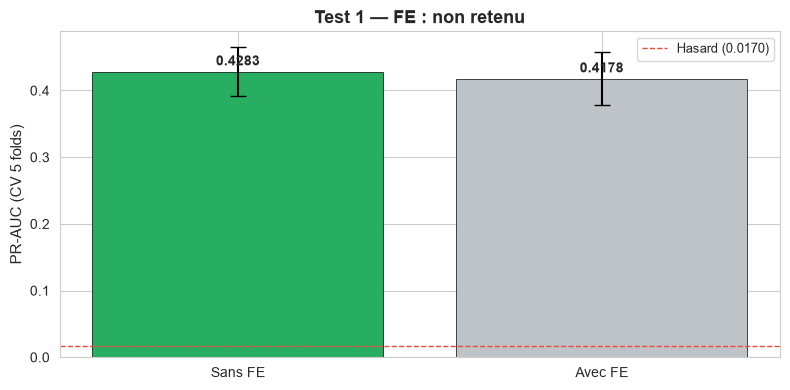

In [11]:
# ============================================================
# 5.1 TEST 1 — FEATURE ENGINEERING (avec vs sans)
# ============================================================
scores_sans_fe = cv_pr_auc(base_cols, X_use=X_train_FE, num_reference=num_cols)
scores_avec_fe = cv_pr_auc(all_cols,  X_use=X_train_FE, num_reference=num_cols_FE)

fe_test = pd.DataFrame([
    {"config": "Sans FE", "n_features": len(base_cols),
     "PR_AUC_mean": scores_sans_fe.mean(), "PR_AUC_std": scores_sans_fe.std()},
    {"config": "Avec FE", "n_features": len(all_cols),
     "PR_AUC_mean": scores_avec_fe.mean(), "PR_AUC_std": scores_avec_fe.std()},
])
print("=== TEST 1 — FEATURE ENGINEERING ===")
print(fe_test.round(4).to_string(index=False))

# Règle simple : on garde FE si le gain moyen > 0.5 * écart-type
delta_fe = scores_avec_fe.mean() - scores_sans_fe.mean()
seuil_bruit = 0.5 * scores_sans_fe.std()
USE_FE = delta_fe > seuil_bruit
print(f"\nDelta (avec − sans) = {delta_fe:+.4f} | bruit = ±{seuil_bruit:.4f}")
print(f"→ Décision : {'Avec FE' if USE_FE else 'Sans FE'}")

fig, ax = plt.subplots(figsize=(8, 4))
colors = [PALETTE["retained"] if (USE_FE and c == "Avec FE")
          or (not USE_FE and c == "Sans FE")
          else PALETTE["rejected"] for c in fe_test["config"]]
bars = ax.bar(fe_test["config"], fe_test["PR_AUC_mean"],
              yerr=fe_test["PR_AUC_std"], color=colors,
              edgecolor="black", linewidth=0.5, capsize=6)
ax.axhline(prevalence, color=PALETTE["fraud"], ls="--", lw=1,
           label=f"Hasard ({prevalence:.4f})")
for bar, v in zip(bars, fe_test["PR_AUC_mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005,
            f"{v:.4f}", ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("PR-AUC (CV 5 folds)")
ax.set_title(f"Test 1 — FE : {'retenu' if USE_FE else 'non retenu'}")
ax.legend()
plt.tight_layout()
plt.savefig("figures/06_test_fe.png", dpi=130, bbox_inches="tight")
plt.show()

=== TEST 2 — SCALER ===
  scaler  PR_AUC_mean  PR_AUC_std
Standard       0.4283      0.0369
  Robust       0.4259      0.0368

Delta (Robust − Standard) = -0.0025 | bruit = ±0.0184
→ Décision : standard


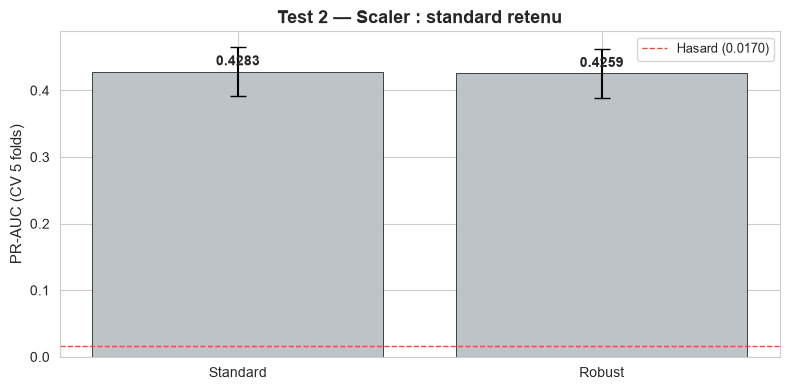

In [12]:
# ============================================================
# 5.2 TEST 2 — SCALER (Standard vs Robust)
# ============================================================
scores_std = cv_pr_auc(base_cols, scaler="standard", num_reference=num_cols)
scores_rob = cv_pr_auc(base_cols, scaler="robust",   num_reference=num_cols)

scaler_test = pd.DataFrame([
    {"scaler": "Standard", "PR_AUC_mean": scores_std.mean(), "PR_AUC_std": scores_std.std()},
    {"scaler": "Robust",   "PR_AUC_mean": scores_rob.mean(), "PR_AUC_std": scores_rob.std()},
])
print("=== TEST 2 — SCALER ===")
print(scaler_test.round(4).to_string(index=False))

delta_sc = scores_rob.mean() - scores_std.mean()
seuil_bruit = 0.5 * scores_std.std()
if delta_sc > seuil_bruit:
    SCALER = "robust"
elif delta_sc < -seuil_bruit:
    SCALER = "standard"
else:
    SCALER = "standard"   # écart dans le bruit → défaut communautaire
print(f"\nDelta (Robust − Standard) = {delta_sc:+.4f} | bruit = ±{seuil_bruit:.4f}")
print(f"→ Décision : {SCALER}")

fig, ax = plt.subplots(figsize=(8, 4))
colors = [PALETTE["retained"] if s == SCALER else PALETTE["rejected"]
          for s in scaler_test["scaler"]]
bars = ax.bar(scaler_test["scaler"], scaler_test["PR_AUC_mean"],
              yerr=scaler_test["PR_AUC_std"], color=colors,
              edgecolor="black", linewidth=0.5, capsize=6)
ax.axhline(prevalence, color=PALETTE["fraud"], ls="--", lw=1,
           label=f"Hasard ({prevalence:.4f})")
for bar, v in zip(bars, scaler_test["PR_AUC_mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005,
            f"{v:.4f}", ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("PR-AUC (CV 5 folds)")
ax.set_title(f"Test 2 — Scaler : {SCALER} retenu")
ax.legend()
plt.tight_layout()
plt.savefig("figures/07_test_scaler.png", dpi=130, bbox_inches="tight")
plt.show()

=== TEST 3 — GESTION DU DÉSÉQUILIBRE ===
               stratégie  PR_AUC_mean  PR_AUC_std
                (a) Rien       0.4283      0.0369
        (b) class_weight       0.4009      0.0578
               (c) SMOTE       0.3879      0.0693
(d) SMOTE + class_weight       0.3879      0.0693

→ Stratégie retenue : (a) Rien (gain de '(a) Rien' dans le bruit (+0.0000 ≤ ±0.0184))


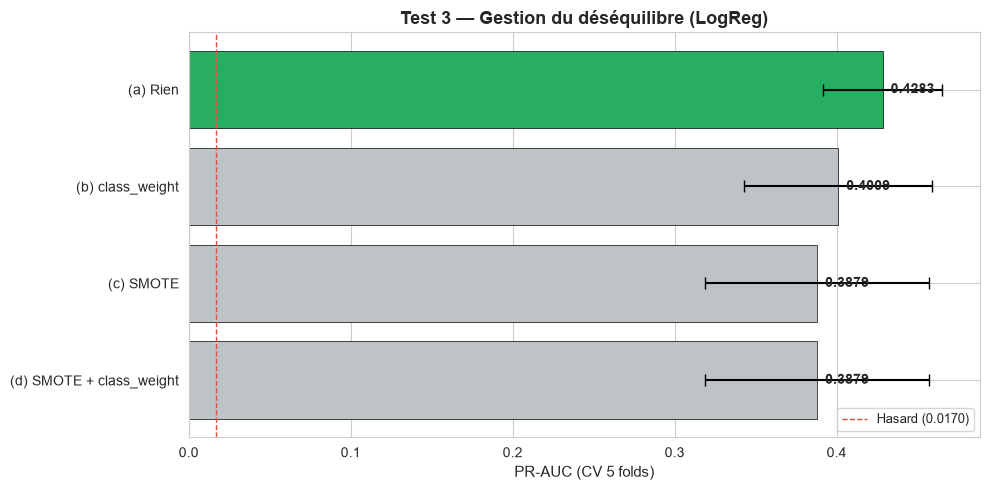

In [13]:
# ============================================================
# 5.3 TEST 3 — GESTION DU DÉSÉQUILIBRE (LogReg)
# ============================================================
# 🔧 CORRECTION : on teste la stratégie sur FINAL_COLS (avec ou sans FE),
# pas seulement sur base_cols, pour que la décision soit cohérente avec
# la config finale.
FINAL_COLS_TEST = all_cols if USE_FE else base_cols
NUM_REF_TEST    = num_cols_FE if USE_FE else num_cols
X_use_test      = X_train_FE

imb_results = []
imb_scores  = {}

# (a) Rien
scores_a = cv_pr_auc(FINAL_COLS_TEST, scaler=SCALER, num_reference=NUM_REF_TEST,
                     X_use=X_use_test)
imb_scores["(a) Rien"] = scores_a
imb_results.append({"stratégie": "(a) Rien",
                    "PR_AUC_mean": scores_a.mean(), "PR_AUC_std": scores_a.std()})

# (b) class_weight
pipe_cw = Pipeline([
    ("pre", build_preprocessor(FINAL_COLS_TEST, scaler=SCALER,
                                num_reference=NUM_REF_TEST)),
    ("model", LogisticRegression(class_weight="balanced",
                                 max_iter=2000, random_state=RANDOM_STATE)),
])
sc = cross_validate(pipe_cw, X_use_test[FINAL_COLS_TEST], y_train, cv=cv,
                    scoring="average_precision", n_jobs=-1)
imb_scores["(b) class_weight"] = sc["test_score"]
imb_results.append({"stratégie": "(b) class_weight",
                    "PR_AUC_mean": sc["test_score"].mean(),
                    "PR_AUC_std":  sc["test_score"].std()})

# (c) SMOTE
pipe_smote = ImbPipeline([
    ("pre", build_preprocessor(FINAL_COLS_TEST, scaler=SCALER,
                                num_reference=NUM_REF_TEST)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
sc = cross_validate(pipe_smote, X_use_test[FINAL_COLS_TEST], y_train, cv=cv,
                    scoring="average_precision", n_jobs=-1)
imb_scores["(c) SMOTE"] = sc["test_score"]
imb_results.append({"stratégie": "(c) SMOTE",
                    "PR_AUC_mean": sc["test_score"].mean(),
                    "PR_AUC_std":  sc["test_score"].std()})

# (d) SMOTE + class_weight
pipe_both = ImbPipeline([
    ("pre", build_preprocessor(FINAL_COLS_TEST, scaler=SCALER,
                                num_reference=NUM_REF_TEST)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(class_weight="balanced",
                                 max_iter=2000, random_state=RANDOM_STATE)),
])
sc = cross_validate(pipe_both, X_use_test[FINAL_COLS_TEST], y_train, cv=cv,
                    scoring="average_precision", n_jobs=-1)
imb_scores["(d) SMOTE + class_weight"] = sc["test_score"]
imb_results.append({"stratégie": "(d) SMOTE + class_weight",
                    "PR_AUC_mean": sc["test_score"].mean(),
                    "PR_AUC_std":  sc["test_score"].std()})

imb_df = pd.DataFrame(imb_results).sort_values("PR_AUC_mean", ascending=False)
print("=== TEST 3 — GESTION DU DÉSÉQUILIBRE ===")
print(imb_df.round(4).to_string(index=False))

# Règle : on retient la meilleure UNIQUEMENT si le gain vs (a) dépasse le bruit
best = imb_df.iloc[0]["stratégie"]
delta_imb = imb_df.iloc[0]["PR_AUC_mean"] - imb_scores["(a) Rien"].mean()
seuil_bruit = 0.5 * imb_scores["(a) Rien"].std()

if best == "(a) Rien" or delta_imb <= seuil_bruit:
    IMB_STRAT = "(a) Rien"
    IMB_JUSTIF = (f"gain de '{best}' dans le bruit "
                  f"({delta_imb:+.4f} ≤ ±{seuil_bruit:.4f})")
else:
    IMB_STRAT = best
    IMB_JUSTIF = f"gain significatif vs (a) Rien ({delta_imb:+.4f})"

print(f"\n→ Stratégie retenue : {IMB_STRAT} ({IMB_JUSTIF})")

fig, ax = plt.subplots(figsize=(10, 5))
plot_imb = imb_df[::-1]
colors = [PALETTE["retained"] if s == IMB_STRAT else PALETTE["rejected"]
          for s in plot_imb["stratégie"]]
bars = ax.barh(plot_imb["stratégie"], plot_imb["PR_AUC_mean"],
               xerr=plot_imb["PR_AUC_std"], color=colors,
               edgecolor="black", linewidth=0.5, capsize=4)
ax.axvline(prevalence, color=PALETTE["fraud"], ls="--", lw=1,
           label=f"Hasard ({prevalence:.4f})")
for bar, v in zip(bars, plot_imb["PR_AUC_mean"]):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f"{v:.4f}", va="center", fontweight="bold")
ax.set_xlabel("PR-AUC (CV 5 folds)")
ax.set_title("Test 3 — Gestion du déséquilibre (LogReg)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/08_test_imbalance.png", dpi=130, bbox_inches="tight")
plt.show()

In [14]:
# ============================================================
# 5.4 SYNTHÈSE DE LA CONFIGURATION
# ============================================================
FINAL_COLS    = all_cols if USE_FE else base_cols
NUM_REF_FINAL = num_cols_FE if USE_FE else num_cols
MIN_FREQ      = 20   # cardinalité des catégorielles faible → peu d'impact

def prepare(df):
    return engineer_features(df) if USE_FE else df.copy()

X_train_model = prepare(X_train)
X_val_model   = prepare(X_val)
X_test_model  = prepare(X_test)

final_config = pd.DataFrame([
    {"dimension": "Feature engineering",
     "retenu": "Avec FE" if USE_FE else "Sans FE"},
    {"dimension": "Scaler", "retenu": SCALER},
    {"dimension": "OneHot min_frequency", "retenu": str(MIN_FREQ)},
    {"dimension": "Gestion du déséquilibre", "retenu": IMB_STRAT},
])

print("=== CONFIGURATION RETENUE ===")
display(final_config)
print(f"\nVariables finales : {len(FINAL_COLS)}")
print(f"Shapes : Train {X_train_model.shape} | Val {X_val_model.shape} | "
      f"Test {X_test_model.shape}")

=== CONFIGURATION RETENUE ===


,dimension,retenu
0,Feature engineering,Sans FE
1,Scaler,standard
2,OneHot min_frequency,20
3,Gestion du déséquilibre,(a) Rien



Variables finales : 24
Shapes : Train (12800, 24) | Val (3200, 24) | Test (4000, 24)


In [15]:
# ============================================================
# 6. PIPELINES CANDIDATS
# ============================================================
def build_final_preprocessor():
    return build_preprocessor(FINAL_COLS, scaler=SCALER,
                               min_freq=MIN_FREQ,
                               num_reference=NUM_REF_FINAL)

def wrap_with_imb(model, use_smote=False, class_weight=None):
    """Construit un pipeline cohérent avec la stratégie d'imbalance choisie.
    🔧 CORRECTION : signale explicitement si un modèle ne supporte pas
    class_weight (HistGB, GradientBoosting) au lieu de l'ignorer en silence."""
    steps = [("pre", build_final_preprocessor())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    if class_weight is not None:
        if "class_weight" in model.get_params():
            model.set_params(class_weight=class_weight)
        else:
            print(f"  ℹ️ {type(model).__name__} ne supporte pas class_weight")
    steps.append(("model", model))
    return ImbPipeline(steps) if use_smote else Pipeline(steps)


use_smote = "SMOTE" in IMB_STRAT
use_cw    = "class_weight" in IMB_STRAT

pipelines = {
    "Dummy (plancher)": Pipeline([
        ("pre", build_final_preprocessor()),
        ("model", DummyClassifier(strategy="prior", random_state=RANDOM_STATE)),
    ]),
    "Baseline (LogReg)": wrap_with_imb(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        use_smote=use_smote,
        class_weight="balanced" if use_cw else None,
    ),
    "GradientBoosting": wrap_with_imb(
        GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=3,
            min_samples_leaf=20, subsample=0.8,
            random_state=RANDOM_STATE),
        use_smote=use_smote,
        class_weight="balanced" if use_cw else None,
    ),
    "HistGB": wrap_with_imb(
        HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=500, max_depth=6,
            min_samples_leaf=20, l2_regularization=1.0,
            early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=30, random_state=RANDOM_STATE),
        use_smote=use_smote,
    ),
    "RF (régularisé)": wrap_with_imb(
        RandomForestClassifier(
            n_estimators=500, max_depth=8, min_samples_leaf=10,
            min_samples_split=20, max_features="sqrt",
            random_state=RANDOM_STATE, n_jobs=-1,
            class_weight="balanced_subsample" if use_cw else None),
        use_smote=use_smote,
    ),
}

print(f"Configuration : FE={USE_FE} | scaler={SCALER} | "
      f"min_freq={MIN_FREQ} | imb={IMB_STRAT}")
print(f"\n{len(pipelines)} pipelines définis :")
for name in pipelines:
    print(f"  • {name}")

Configuration : FE=False | scaler=standard | min_freq=20 | imb=(a) Rien

5 pipelines définis :
  • Dummy (plancher)
  • Baseline (LogReg)
  • GradientBoosting
  • HistGB
  • RF (régularisé)


In [16]:
# ============================================================
# 7. CROSS-VALIDATION FINALE (sur Train)
# ============================================================
SCORING = {
    "PR_AUC":     "average_precision",
    "ROC_AUC":    "roc_auc",
    "F1_seuil05": "f1",
    "MCC":        "matthews_corrcoef",
    "BalAcc":     "balanced_accuracy",
}

cv_results = {}
for name, pipe in pipelines.items():
    print(f"  → CV {name}…", end=" ")
    cv_results[name] = cross_validate(
        pipe, X_train_model[FINAL_COLS], y_train, cv=cv,
        scoring=SCORING, n_jobs=-1, error_score="raise")
    print(f"PR-AUC = {cv_results[name]['test_PR_AUC'].mean():.4f}")

rows = []
for name, res in cv_results.items():
    row = {"Modèle": name}
    for m in SCORING:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
    row["Temps (s)"] = res["fit_time"].mean()
    rows.append(row)

cv_table = (pd.DataFrame(rows).set_index("Modèle")
              .sort_values("PR_AUC_mean", ascending=False))

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("\n=== RÉSULTATS CV ===")
print(cv_table[["PR_AUC_mean", "PR_AUC_std", "ROC_AUC_mean",
                "F1_seuil05_mean", "MCC_mean", "BalAcc_mean", "Temps (s)"]])

  → CV Dummy (plancher)… PR-AUC = 0.0170
  → CV Baseline (LogReg)… PR-AUC = 0.4283
  → CV GradientBoosting… PR-AUC = 0.3512
  → CV HistGB… PR-AUC = 0.2359
  → CV RF (régularisé)… PR-AUC = 0.3016

=== RÉSULTATS CV ===
                   PR_AUC_mean  PR_AUC_std  ROC_AUC_mean  F1_seuil05_mean  \
Modèle                                                                      
Baseline (LogReg)       0.4283      0.0369        0.9453           0.3401   
GradientBoosting        0.3512      0.0645        0.9296           0.2114   
RF (régularisé)         0.3016      0.0477        0.9247           0.0000   
HistGB                  0.2359      0.0285        0.9117           0.0551   
Dummy (plancher)        0.0170      0.0002        0.5000           0.0000   

                   MCC_mean  BalAcc_mean  Temps (s)  
Modèle                                               
Baseline (LogReg)    0.3873       0.6141     0.0745  
GradientBoosting     0.2590       0.5658     3.5566  
RF (régularisé)      0.0000

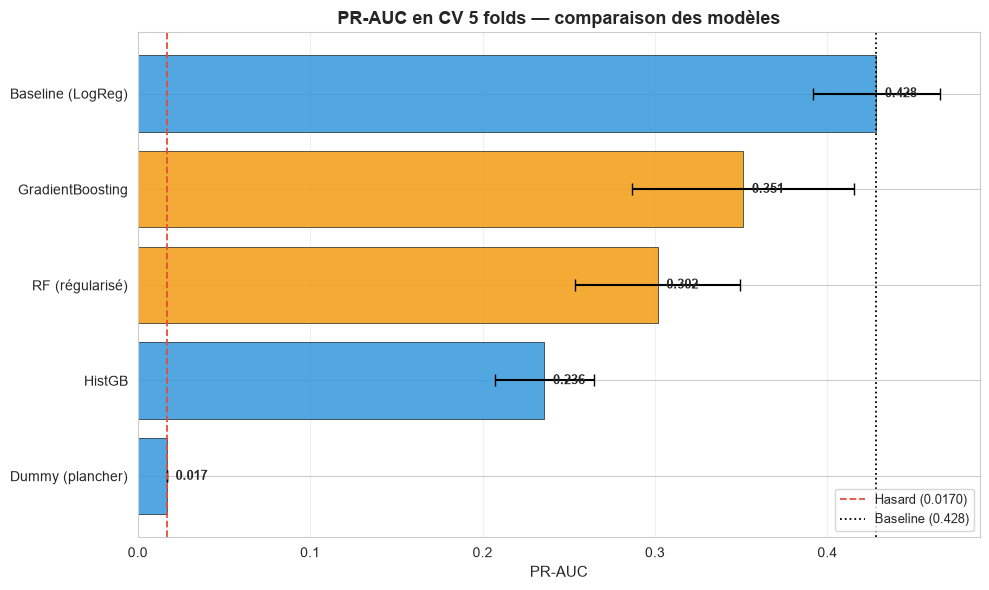


Lift vs hasard :
Modèle
Baseline (LogReg)   25.3000
GradientBoosting    20.7000
RF (régularisé)     17.8000
HistGB              13.9000
Dummy (plancher)     1.0000


In [17]:
# ============================================================
# 7.1 VISUALISATION CV
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = cv_table["PR_AUC_mean"].sort_values()
err = cv_table.loc[plot_data.index, "PR_AUC_std"]
colors = [PALETTE["accent"] if "Boosting" in m or "RF" in m
          else PALETTE["primary"] for m in plot_data.index]
bars = ax.barh(plot_data.index, plot_data.values, xerr=err.values,
               color=colors, alpha=0.85, edgecolor="black",
               linewidth=0.5, capsize=4)
ax.axvline(prevalence, color=PALETTE["fraud"], ls="--", lw=1.3,
           label=f"Hasard ({prevalence:.4f})")
baseline = cv_table.loc["Baseline (LogReg)", "PR_AUC_mean"]
ax.axvline(baseline, color="black", ls=":", lw=1.3,
           label=f"Baseline ({baseline:.3f})")
for bar, v in zip(bars, plot_data.values):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2, f"{v:.3f}",
            va="center", fontsize=9, fontweight="bold")
ax.set_xlabel("PR-AUC")
ax.set_title("PR-AUC en CV 5 folds — comparaison des modèles")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/09_cv_prauc.png", dpi=130, bbox_inches="tight")
plt.show()

lift = (cv_table["PR_AUC_mean"] / prevalence).sort_values(ascending=False)
print("\nLift vs hasard :")
print(lift.round(1).to_string())

In [18]:
# ============================================================
# 8. CHOIX DU SEUIL SUR VALIDATION
# ============================================================
best_name = cv_table.index[0]
best_pipe = pipelines[best_name].fit(X_train_model[FINAL_COLS], y_train)
print(f"Meilleur modèle (CV Train) : {best_name}\n")

y_val_proba = best_pipe.predict_proba(X_val_model[FINAL_COLS])[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (
    precisions[:-1] + recalls[:-1] + 1e-12)

# 1) F1 max
idx_f1 = np.argmax(f1_scores)
thr_f1 = thresholds[idx_f1]

# 2) Youden
fpr, tpr, thr_roc = roc_curve(y_val, y_val_proba)
idx_youden = np.argmax(tpr - fpr)
thr_youden = thr_roc[idx_youden]

# 3) Recall cible
RECALL_TARGET = 0.80
mask_r = recalls[:-1] >= RECALL_TARGET
thr_recall = thresholds[np.argmax(np.where(mask_r, precisions[:-1], -1))] \
             if mask_r.any() else np.nan

# 4) Précision cible
PRECISION_TARGET = 0.30
mask_p = precisions[:-1] >= PRECISION_TARGET
thr_prec = thresholds[np.argmax(np.where(mask_p, recalls[:-1], -1))] \
           if mask_p.any() else np.nan

# 5) Top X %
ALERT_BUDGET_PCT = 5.0
thr_pct = np.percentile(y_val_proba, 100 - ALERT_BUDGET_PCT)


def metrics_at(thr):
    y_pred = (y_val_proba >= thr).astype(int)
    tp = ((y_pred == 1) & (y_val == 1)).sum()
    fp = ((y_pred == 1) & (y_val == 0)).sum()
    fn = ((y_pred == 0) & (y_val == 1)).sum()
    tn = ((y_pred == 0) & (y_val == 0)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2*p*r/(p+r) if (p+r) > 0 else 0
    return {"thr": thr, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": p, "recall": r, "f1": f1, "n_alerts": tp + fp}


seuils = {
    "1. F1 max":                                    thr_f1,
    "2. Youden's J":                                thr_youden,
    f"3. Recall cible = {RECALL_TARGET:.2f}":       thr_recall,
    f"4. Precision cible = {PRECISION_TARGET:.2f}": thr_prec,
    f"5. Top {ALERT_BUDGET_PCT:.1f} %":             thr_pct,
}
seuils = {k: v for k, v in seuils.items() if not np.isnan(v)}

print("Seuils calculés (sur Validation) :")
for name, thr in seuils.items():
    print(f"  {name:40s} → seuil = {thr:.4f}")

if np.isnan(thr_prec):
    print("  ⚠️ Précision cible infaisable → seuil 4 non utilisé")

Meilleur modèle (CV Train) : Baseline (LogReg)

Seuils calculés (sur Validation) :
  1. F1 max                                → seuil = 0.2522
  2. Youden's J                            → seuil = 0.0249
  3. Recall cible = 0.80                   → seuil = 0.0164
  4. Precision cible = 0.30                → seuil = 0.1607
  5. Top 5.0 %                             → seuil = 0.0673


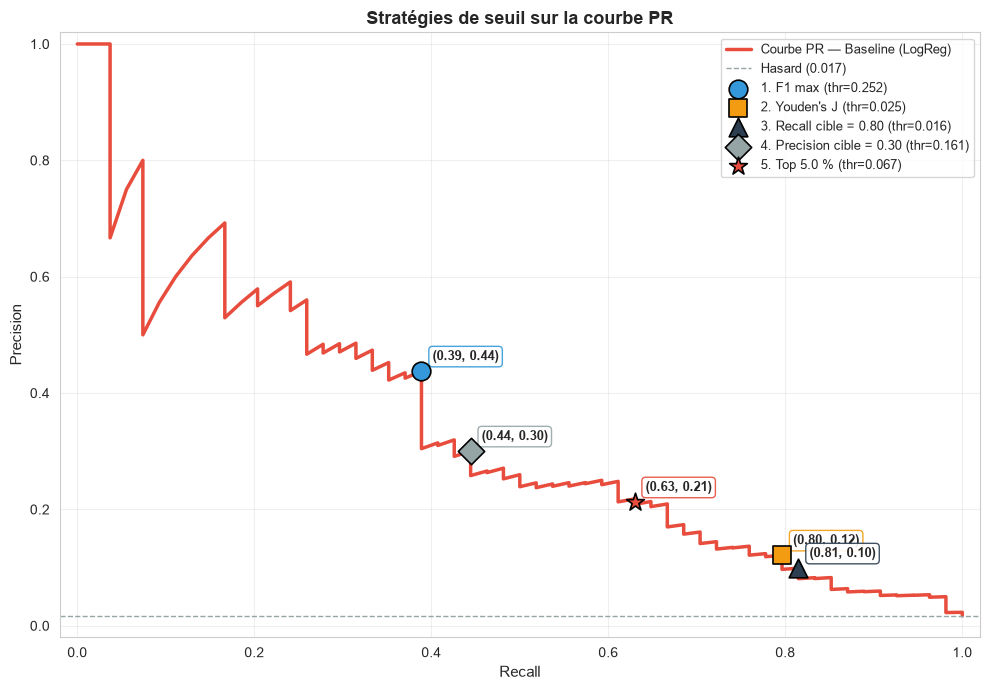

In [19]:
# ============================================================
# 8.1 COURBE PRECISION-RECALL AVEC STRATÉGIES
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(recalls, precisions, color=PALETTE["fraud"], lw=2.5,
        label=f"Courbe PR — {best_name}")
ax.axhline(y_val.mean(), color=PALETTE["gray"], ls="--", lw=1,
           label=f"Hasard ({y_val.mean():.3f})")

markers  = ["o", "s", "^", "D", "*"]
colors_m = [PALETTE["primary"], PALETTE["accent"], PALETTE["dark"],
            PALETTE["gray"], PALETTE["fraud"]]

for (name, thr), marker, color in zip(seuils.items(), markers, colors_m):
    m = metrics_at(thr)
    ax.scatter(m["recall"], m["precision"], s=180, marker=marker,
               color=color, edgecolor="black", linewidth=1.2, zorder=5,
               label=f"{name} (thr={thr:.3f})")
    ax.annotate(f"({m['recall']:.2f}, {m['precision']:.2f})",
                xy=(m["recall"], m["precision"]),
                xytext=(8, 8), textcoords="offset points",
                fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", fc="white",
                          ec=color, alpha=0.9))

ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Stratégies de seuil sur la courbe PR")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
plt.tight_layout()
plt.savefig("figures/10_PR_strategies.png", dpi=130, bbox_inches="tight")
plt.show()

In [20]:
# ============================================================
# 9. SEUIL FINAL RETENU
# ============================================================
m_f1max = metrics_at(thr_f1)

if np.isnan(thr_recall):
    SEUIL_RETENU = thr_f1
    SEUIL_JUSTIF = "Fallback F1 max (recall cible infaisable)"
elif m_f1max["recall"] < 0.70:
    SEUIL_RETENU = thr_recall
    SEUIL_JUSTIF = (f"F1 max a un recall trop faible "
                    f"({m_f1max['recall']:.2f}) → recall cible")
else:
    SEUIL_RETENU = thr_f1
    SEUIL_JUSTIF = f"F1 max retenu (rappel = {m_f1max['recall']:.2f} ≥ 0.70)"

m_final = metrics_at(SEUIL_RETENU)
print("=== SEUIL FINAL (Validation) ===")
print(f"  Seuil         : {SEUIL_RETENU:.4f}")
print(f"  Justification : {SEUIL_JUSTIF}")
print(f"  Precision     : {m_final['precision']:.4f}")
print(f"  Recall        : {m_final['recall']:.4f}")
print(f"  F1            : {m_final['f1']:.4f}")
print(f"  Alertes       : {m_final['n_alerts']} (dont {m_final['TP']} vraies fraudes)")
print(f"  Fraudes ratées: {m_final['FN']} / {m_final['FN'] + m_final['TP']}")

=== SEUIL FINAL (Validation) ===
  Seuil         : 0.0164
  Justification : F1 max a un recall trop faible (0.39) → recall cible
  Precision     : 0.0989
  Recall        : 0.8148
  F1            : 0.1764
  Alertes       : 445 (dont 44 vraies fraudes)
  Fraudes ratées: 10 / 54


=== ÉVALUATION FINALE SUR TEST ===
Modèle : Baseline (LogReg) | Seuil : 0.0164

PR-AUC      : 0.4598
ROC-AUC     : 0.9516
F1          : 0.1971
Precision   : 0.1107
Recall      : 0.8971
MCC         : 0.2897
Balanced acc: 0.8862

--- Classification report ---
              precision    recall  f1-score   support

    Légitime       1.00      0.88      0.93      3932
      Fraude       0.11      0.90      0.20        68

    accuracy                           0.88      4000
   macro avg       0.55      0.89      0.56      4000
weighted avg       0.98      0.88      0.92      4000



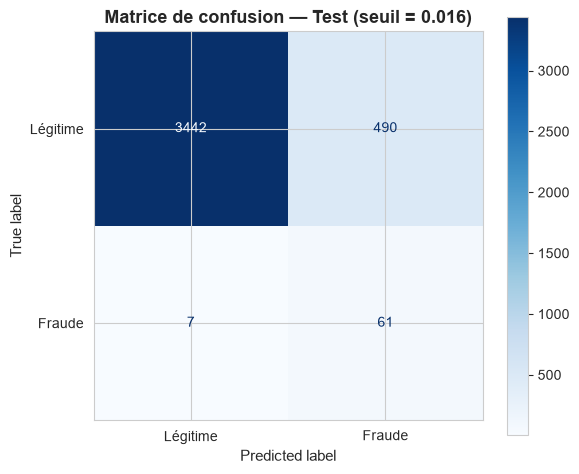


--- Stabilité Val vs Test ---
  PR-AUC   : Val = 0.3395 | Test = 0.4598
  Recall   : Val = 0.8148 | Test = 0.8971
  Precision: Val = 0.0989 | Test = 0.1107


In [21]:
# ============================================================
# 10. ÉVALUATION FINALE SUR TEST (une seule fois)
# ============================================================
y_test_proba = best_pipe.predict_proba(X_test_model[FINAL_COLS])[:, 1]
y_test_pred  = (y_test_proba >= SEUIL_RETENU).astype(int)

print("=== ÉVALUATION FINALE SUR TEST ===")
print(f"Modèle : {best_name} | Seuil : {SEUIL_RETENU:.4f}\n")

print(f"PR-AUC      : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"F1          : {f1_score(y_test, y_test_pred):.4f}")
print(f"Precision   : {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall      : {recall_score(y_test, y_test_pred):.4f}")
print(f"MCC         : {matthews_corrcoef(y_test, y_test_pred):.4f}")
print(f"Balanced acc: {balanced_accuracy_score(y_test, y_test_pred):.4f}")

print("\n--- Classification report ---")
print(classification_report(y_test, y_test_pred,
                            target_names=["Légitime", "Fraude"]))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Légitime", "Fraude"])
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"Matrice de confusion — Test (seuil = {SEUIL_RETENU:.3f})")
plt.tight_layout()
plt.savefig("figures/11_confusion_test.png", dpi=130, bbox_inches="tight")
plt.show()

# Stabilité Val vs Test
pr_val  = average_precision_score(y_val, y_val_proba)
pr_test = average_precision_score(y_test, y_test_proba)
print(f"\n--- Stabilité Val vs Test ---")
print(f"  PR-AUC   : Val = {pr_val:.4f} | Test = {pr_test:.4f}")
print(f"  Recall   : Val = {m_final['recall']:.4f} | "
      f"Test = {recall_score(y_test, y_test_pred):.4f}")
print(f"  Precision: Val = {m_final['precision']:.4f} | "
      f"Test = {precision_score(y_test, y_test_pred):.4f}")

Calcul de la permutation importance…

Top 10 features :
                     feature  importance_mean  importance_std
             cvv_retry_count           0.2331          0.0191
         merchant_risk_score           0.2021          0.0091
              velocity_score           0.1894          0.0137
   billing_shipping_mismatch           0.1102          0.0163
         ip_country_mismatch           0.0913          0.0242
                 auth_method           0.0912          0.0267
is_ai_generated_scam_attempt           0.0902          0.0185
                    used_vpn           0.0757          0.0099
             is_new_merchant           0.0679          0.0233
      is_foreign_transaction           0.0332          0.0172


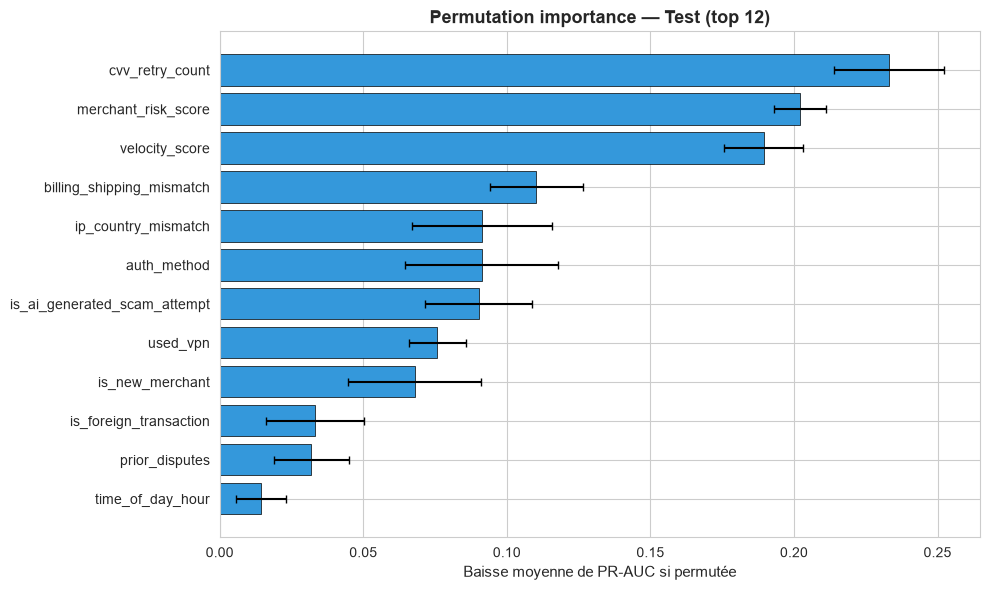

In [22]:
# ============================================================
# 11. PERMUTATION IMPORTANCE (sur Test)
# ============================================================
print("Calcul de la permutation importance…")
perm_result = permutation_importance(
    best_pipe, X_test_model[FINAL_COLS], y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": FINAL_COLS,
    "importance_mean": perm_result.importances_mean,
    "importance_std":  perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

print("\nTop 10 features :")
print(perm_df.head(10).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
top_perm = perm_df.head(12).iloc[::-1]
ax.barh(top_perm["feature"], top_perm["importance_mean"],
        xerr=top_perm["importance_std"], color=PALETTE["primary"],
        edgecolor="black", linewidth=0.5, capsize=3)
ax.set_xlabel("Baisse moyenne de PR-AUC si permutée")
ax.set_title("Permutation importance — Test (top 12)")
plt.tight_layout()
plt.savefig("figures/12_permutation_importance.png", dpi=130, bbox_inches="tight")
plt.show()

In [23]:
# ============================================================
# 12. SAUVEGARDE DU MODÈLE FINAL
# ============================================================
joblib.dump(
    {"pipeline": best_pipe,
     "seuil":    SEUIL_RETENU,
     "features": FINAL_COLS,
     "use_fe":   USE_FE,
     "scaler":   SCALER,
     "min_freq": MIN_FREQ,
     "imb_strat": IMB_STRAT},
    "models/final_model.joblib"
)
print("✓ Modèle sauvegardé dans models/final_model.joblib")

# Vérification du rechargement
loaded = joblib.load("models/final_model.joblib")
_proba_check = loaded["pipeline"].predict_proba(
    X_test_model[loaded["features"]])[:, 1]
assert np.allclose(_proba_check, y_test_proba), "Erreur de rechargement !"
print("✓ Rechargement vérifié — prédictions identiques")

✓ Modèle sauvegardé dans models/final_model.joblib
✓ Rechargement vérifié — prédictions identiques


In [24]:
# ============================================================
# 14. SAUVEGARDE DES ARTEFACTS POUR LE DASHBOARD
# ============================================================
import numpy as np
from pathlib import Path

Path("models").mkdir(exist_ok=True)

# Prédictions sur Test (déjà calculées dans ton notebook)
np.save("models/proba_test.npy", y_test_proba)
np.save("models/y_test.npy", y_test.values)

# Noms des features après préprocessing (pour l'onglet Coefficients)
preprocessor = best_pipe.named_steps["pre"]
feature_names = preprocessor.get_feature_names_out()
np.save("models/feature_names.npy", feature_names)

# Coefficients du modèle (LogReg)
if hasattr(best_pipe.named_steps["model"], "coef_"):
    np.save("models/coefs.npy", best_pipe.named_steps["model"].coef_[0])

print("✓ Artefacts sauvegardés dans models/")
print(f"  - proba_test.npy       ({len(y_test_proba)} scores)")
print(f"  - y_test.npy           ({len(y_test)} labels)")
print(f"  - feature_names.npy    ({len(feature_names)} features)")
print(f"  - coefs.npy            ({len(feature_names)} coefficients)")

✓ Artefacts sauvegardés dans models/
  - proba_test.npy       (4000 scores)
  - y_test.npy           (4000 labels)
  - feature_names.npy    (54 features)
  - coefs.npy            (54 coefficients)
